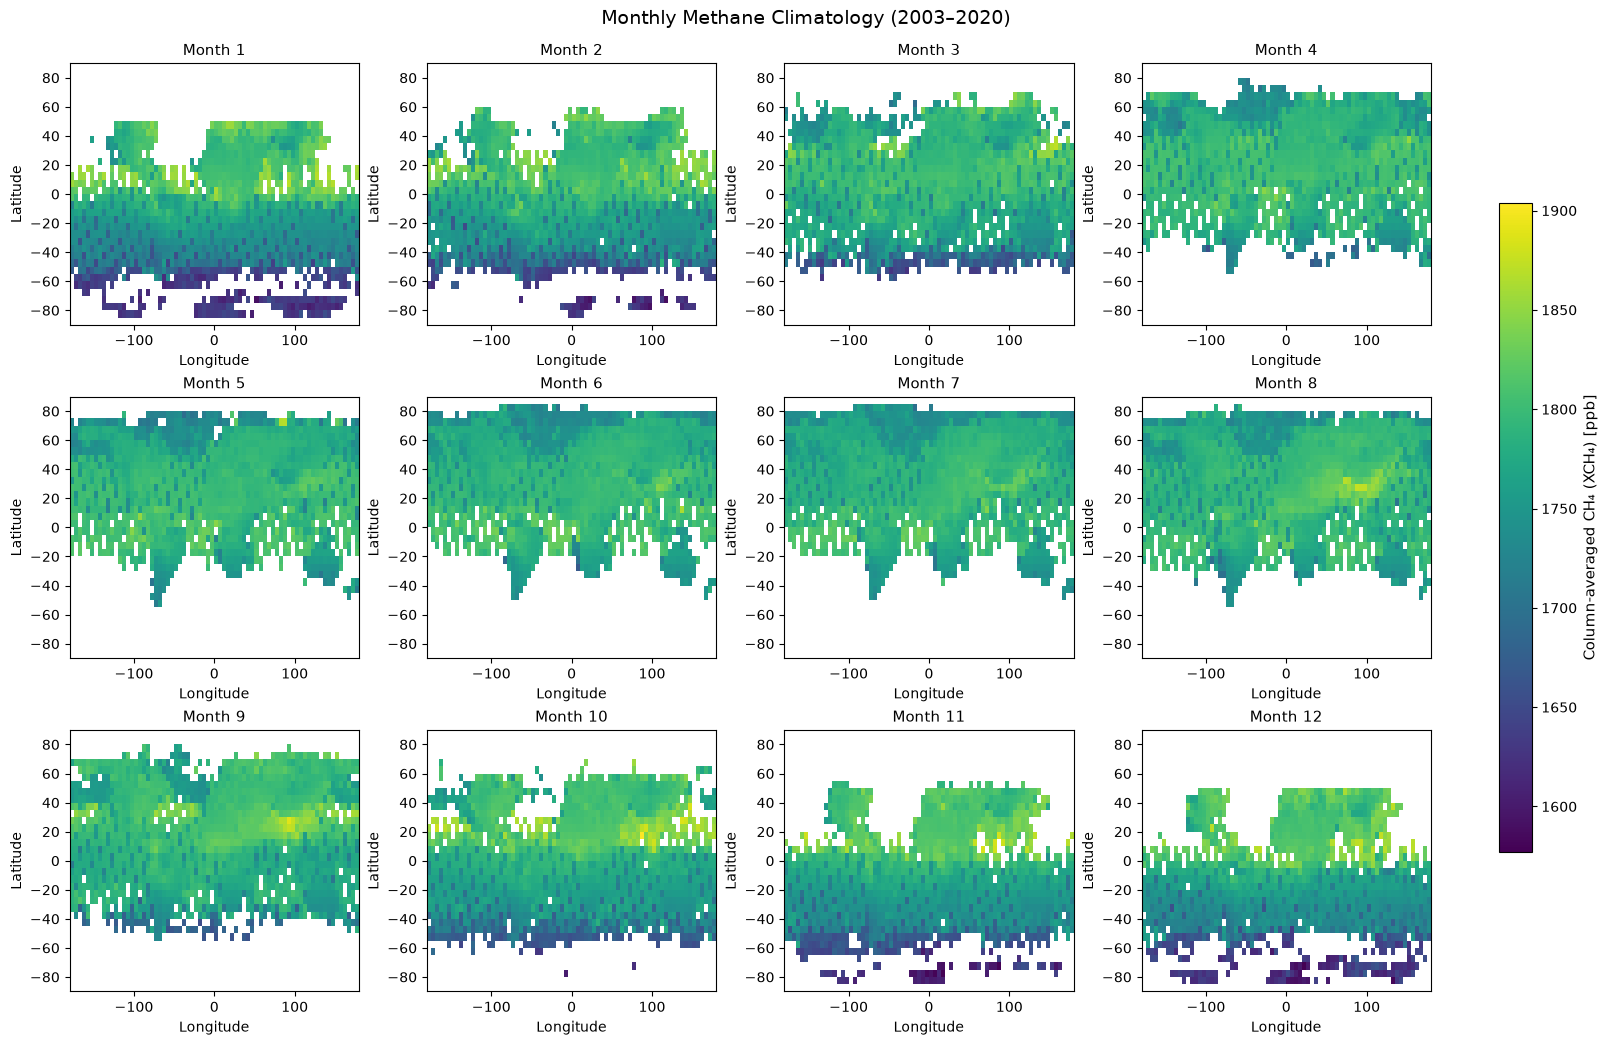

In [6]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
fn = "200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc"
ds = xr.open_dataset(fn)
xch4 = ds["xch4"]
#去掉异常值
xch4 = xch4.where(xch4 != 1e20)
#换单位
xch4 = xch4 * 1000000000
#根据时间中的月份分组，所有年份同一月份求平均
climatology = xch4.groupby("time.month").mean("time")
#设置排版和尺寸，自动调整子图位置
fig, axes = plt.subplots(3, 4, figsize=(16, 10), constrained_layout=True)
#将原来的二维（几行几列的图）转成一维（第几张图），方便 for循环
axes = axes.flatten()
#找到最大值最小值，作为统一颜色条的上下限
vmin, vmax = climatology.min().item(), climatology.max().item()
for month_num in range(1, 13):
    ax = axes[month_num - 1]
    # 修复：把 i → month_num - 1
    im = climatology.isel(month=month_num - 1).plot(
        ax=ax,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        #不单独放颜色条，最后放1个统一的
        add_colorbar=False
    )
    ax.set_title(f"Month {month_num}", fontsize=11)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
cbar = fig.colorbar(im, ax=axes, shrink=0.7)
cbar.set_label("Column-averaged CH₄ (XCH₄) [ppb]", fontsize=11)
fig.suptitle("Monthly Methane Climatology (2003–2020)", fontsize=14, y=1.03)
plt.savefig("Monthly Methane Climatology (2003–2020).png", dpi=300, bbox_inches="tight")
plt.show()

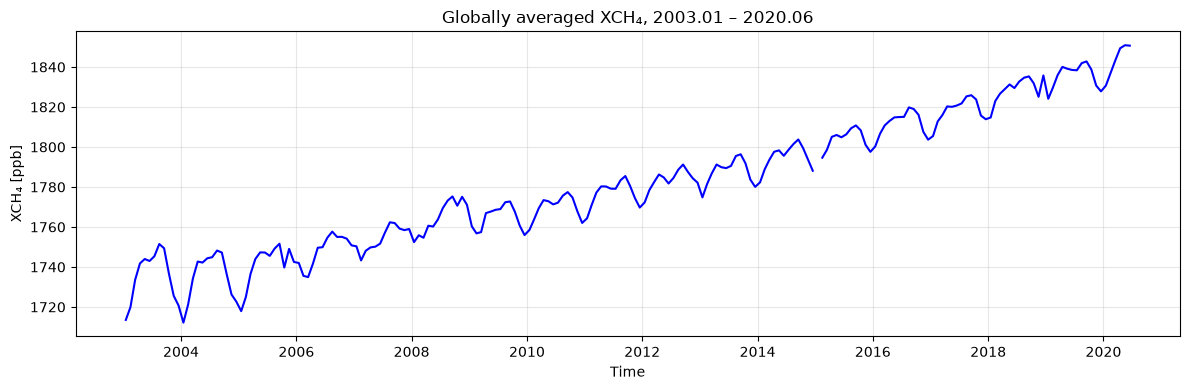

In [7]:
#角度转弧度
lat_weight = np.cos(np.deg2rad(xch4.lat))
#带上纬度面积权重，对经度、纬度两个维度求平均
ch4_global = xch4.weighted(lat_weight).mean(dim=["lon", "lat"])
fig, ax = plt.subplots(figsize=(12, 4))
ch4_global.plot(ax=ax, color="blue", lw=1.5)
ax.set_title("Globally averaged XCH₄, 2003.01 – 2020.06")
ax.set_ylabel("XCH₄ [ppb]")
ax.set_xlabel("Time")
ax.grid(alpha=0.3)
# 关闭y轴偏移，消除左上角标记
ax.yaxis.get_major_formatter().set_useOffset(False)
ax.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.savefig("Globally averaged XCH₄, 2003.01 – 2020.06.png", dpi=300)
plt.show()

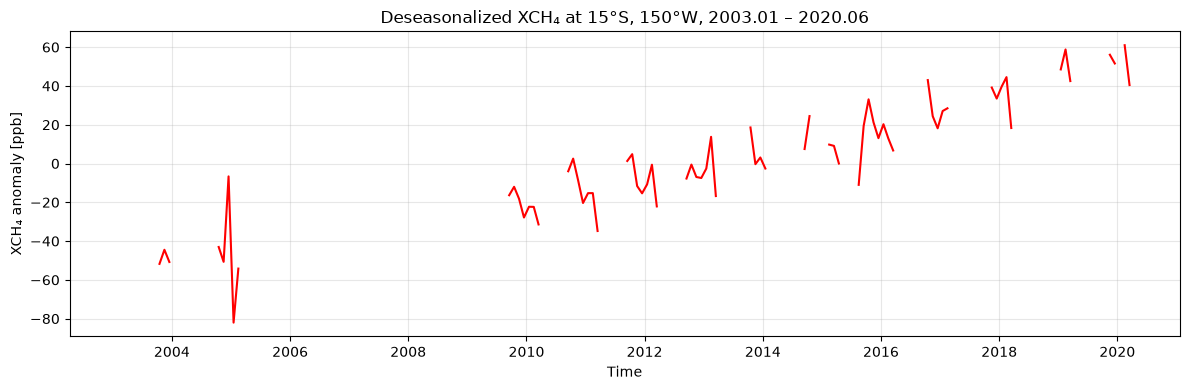

In [8]:
#找距离最近的网格点
site = xch4.sel(lat=-15, lon=-150, method="nearest")
#同一个月不同年的平均
site_climatology = site.groupby("time.month").mean("time")
#修复：正确去季节化，site_clim 改成 site_climatology，写法修正
ch4_deseason = site - site_climatology.sel(month=site.time.dt.month)

fig, ax = plt.subplots(figsize=(12, 4))
ch4_deseason.plot(ax=ax, color="red", lw=1.5)
ax.set_title("Deseasonalized XCH₄ at 15°S, 150°W, 2003.01 – 2020.06")
ax.set_ylabel("XCH₄ anomaly [ppb]")
ax.set_xlabel("Time")
ax.grid(alpha=0.3)
# 关闭y轴偏移，消除左上角标记
ax.yaxis.get_major_formatter().set_useOffset(False)
ax.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.savefig("Deseasonalized XCH₄ at 15°S, 150°W, 2003.01 – 2020.06.png", dpi=300)
plt.show()